# 05 · Application-Time Risk Drivers

**Objective:** find variables available **at the time of application** that separate good from bad borrowers: the first step toward a scorecard / PD model.

**Bottom line:** **income and home ownership both carry signal, but far less than grade.** The bad rate falls monotonically from 19.6% (income < \$40k) to 10.3% (≥ \$100k), a 1.9× spread; renters default more than mortgage holders (17.2% vs. 11.8%, 1.5×). For comparison, grade spans 7.8×.

**Rule for feature selection:** only use information **available at the decision point**. Post-origination fields such as `total_pymnt`, `recoveries`, `last_pymnt_d`, `last_fico_range_high` and `debt_settlement_flag` encode the outcome and would cause **data leakage**.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Home ownership

In [2]:
con.sql("""
SELECT home_ownership,
       COUNT(*)                                         AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)  AS pct_loans,
       CAST(SUM(bad_flag) AS INTEGER)                   AS n_bad,
       ROUND(AVG(bad_flag), 4)                          AS bad_rate
FROM cohort
GROUP BY home_ownership
ORDER BY bad_rate DESC
""").df()

,home_ownership,n_loans,pct_loans,n_bad,bad_rate
0,RENT,191283,0.4291,32857,0.1718
1,OWN,48309,0.1084,7420,0.1536
2,MORTGAGE,206149,0.4625,24231,0.1176
3,ANY,2,0.0000,0,0.0000


* **Renters are riskiest (17.2%)**: fewer assets to absorb a shock.
* **Counter-intuitive:** mortgage holders (11.8%) default less than outright owners (15.4%). A plausible explanation is that a mortgage implies having passed a bank's underwriting, while outright owners include inherited / older, lower-income borrowers. *Hypothesis; to be tested against income.*
* `ANY` has **2 loans**, too few to read; in a scorecard it would be merged into another bin. Sample size is judged on **absolute counts** (and number of bads), not share: OWN at 10.8% still has 48k loans.

## 2. Income bands (binning)
Income is continuous, so it is binned before computing rates. Rules applied:
* every loan falls in **exactly one** bin (lower bound inclusive; a `> 100000` boundary originally dropped **8,430 loans reporting exactly \$100,000**, a common round number);
* missing values get their **own bin** instead of falling into `ELSE`;
* numeric prefixes keep text labels in the right sort order.

In [3]:
income = con.sql("""
SELECT CASE
           WHEN annual_inc IS NULL  THEN '0. Missing'
           WHEN annual_inc < 40000  THEN '1. <40k'
           WHEN annual_inc < 60000  THEN '2. 40-60k'
           WHEN annual_inc < 80000  THEN '3. 60-80k'
           WHEN annual_inc < 100000 THEN '4. 80-100k'
           ELSE                          '5. 100k+'
       END                                              AS income_band,
       COUNT(*)                                         AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)  AS pct_loans,
       ROUND(AVG(bad_flag), 4)                          AS bad_rate
FROM cohort
GROUP BY income_band
ORDER BY income_band
""").df()

assert income["n_loans"].sum() == con.execute("SELECT COUNT(*) FROM cohort").fetchone()[0], "bins must cover every loan"
income

,income_band,n_loans,pct_loans,bad_rate
0,1. <40k,83107,0.1864,0.1961
1,2. 40-60k,120993,0.2714,0.1561
2,3. 60-80k,96892,0.2174,0.1382
3,4. 80-100k,58956,0.1323,0.1201
4,5. 100k+,85795,0.1925,0.1033


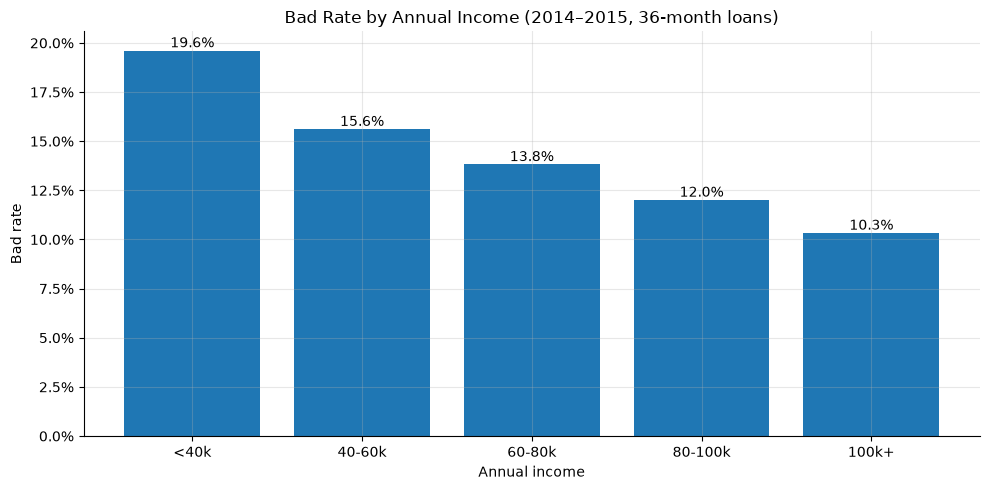

In [4]:
fig, ax = plt.subplots()
ax.bar(income["income_band"].str[3:], income["bad_rate"])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Bad Rate by Annual Income (2014–2015, 36-month loans)")
ax.set_xlabel("Annual income")
ax.set_ylabel("Bad rate")
for x, y in zip(income["income_band"].str[3:], income["bad_rate"]):
    ax.annotate(f"{y:.1%}", (x, y), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bad_rate_by_income.png", dpi=150)
plt.show()

* The trend is **monotonic**, a requirement for scorecard bins (risk must move in one direction to be explainable to business and regulators).
* The biggest absolute step is < \$40k → \$40–60k (−4.0 pp); afterwards each band drops ~1.8 pp, which is still a **13–15% relative** reduction per band.

## 3. Separation power: quick comparison

In [5]:
def spread(sql_expr):
    r = con.execute(f"""
        SELECT MAX(bad_rate) / MIN(bad_rate) AS max_min_ratio
        FROM (SELECT {sql_expr} AS bucket, AVG(bad_flag) AS bad_rate, COUNT(*) AS n
              FROM cohort GROUP BY bucket HAVING COUNT(*) >= 300)
    """).fetchone()[0]
    return round(r, 1)

pd.DataFrame({
    "variable": ["grade", "annual income (5 bands)", "home_ownership"],
    "max / min bad rate": [
        spread("grade"),
        spread("CASE WHEN annual_inc < 40000 THEN 1 WHEN annual_inc < 60000 THEN 2 "
               "WHEN annual_inc < 80000 THEN 3 WHEN annual_inc < 100000 THEN 4 ELSE 5 END"),
        spread("home_ownership"),
    ],
})

,variable,max / min bad rate
0,grade,7.8
1,annual income (5 bands),1.9
2,home_ownership,1.5


*Buckets with fewer than 300 loans (e.g. `ANY`, 2 loans) are excluded from the ratio.*

## 4. Limitations & next steps
* These are **single-variable** views. Income and home ownership are likely correlated, so their effects will not simply add up.
* **Next:** compute **WOE / Information Value** for all application-time variables (DTI, employment length, purpose, FICO at origination, revolving utilization, …), then fit a multivariate **PD model** (logistic scorecard and gradient boosting) with **grade as the benchmark** to beat.